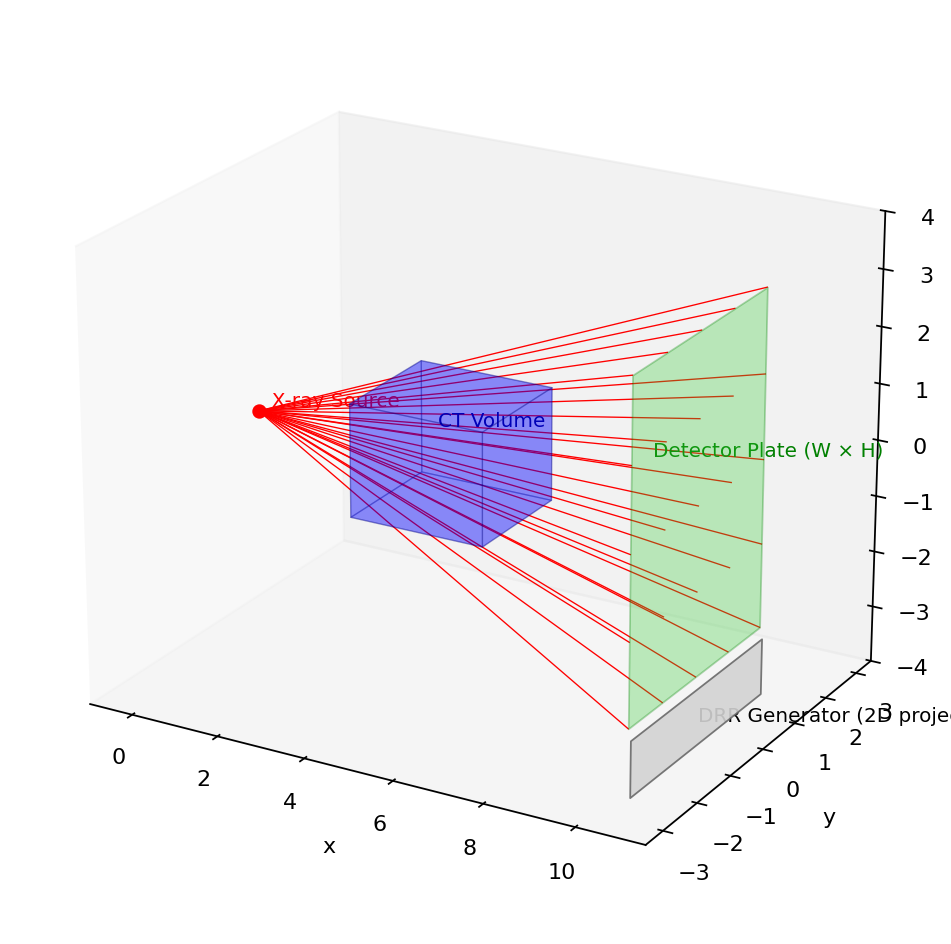

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ---- Scene parameters
source = np.array([0.0, 0.0, 0.0])

xd = 10.0   # detector plane x-position
W, H = 6.0, 4.0
cy, cz = 0.0, 0.0

# CT cube (min corner and sizes)
cube_min = np.array([3.0, -1.0, -1.0])
cube_size = np.array([3.0,  2.0,  2.0])
cube_max = cube_min + cube_size

# ---- Build detector plane corners
D1 = np.array([xd, cy - H/2, cz - W/2])
D2 = np.array([xd, cy + H/2, cz - W/2])
D3 = np.array([xd, cy + H/2, cz + W/2])
D4 = np.array([xd, cy - H/2, cz + W/2])

# ---- Create figure
fig = plt.figure(figsize=(8, 6), dpi=160)
ax = fig.add_subplot(111, projection='3d')

# ---- Plot source
ax.scatter(*source, s=30, color='red')
ax.text(*source, "  X-ray Source", color='red', fontsize=9, ha='left', va='bottom')

# ---- Plot CT cube as semi-transparent blue
x0, y0, z0 = cube_min
x1, y1, z1 = cube_max

verts = [
    # bottom, top
    [(x0,y0,z0),(x1,y0,z0),(x1,y1,z0),(x0,y1,z0)],
    [(x0,y0,z1),(x1,y0,z1),(x1,y1,z1),(x0,y1,z1)],
    # sides
    [(x0,y0,z0),(x1,y0,z0),(x1,y0,z1),(x0,y0,z1)],
    [(x0,y1,z0),(x1,y1,z0),(x1,y1,z1),(x0,y1,z1)],
    [(x0,y0,z0),(x0,y1,z0),(x0,y1,z1),(x0,y0,z1)],
    [(x1,y0,z0),(x1,y1,z0),(x1,y1,z1),(x1,y0,z1)]
]
cube = Poly3DCollection(verts, alpha=0.25, facecolor='blue', edgecolor='navy', linewidths=0.6)
ax.add_collection3d(cube)
ax.text((x0+x1)/2, y1+0.15, (z0+z1)/2, "CT Volume", color='navy', fontsize=9, ha='center')

# ---- Plot detector plane as semi-transparent green
det_verts = [[D1, D2, D3, D4]]
det = Poly3DCollection(det_verts, alpha=0.30, facecolor='limegreen', edgecolor='green', linewidths=0.8)
ax.add_collection3d(det)
ax.text(xd, cy + H/2 + 0.15, cz, "Detector Plate (W × H)", color='green', fontsize=9, ha='center')

# ---- DRR Generator block (thin rectangle below detector)
B1 = np.array([xd + 0.05, cy - H/2, cz - W/2 - 1.2])
B2 = np.array([xd + 0.05, cy + H/2, cz - W/2 - 1.2])
B3 = np.array([xd + 0.05, cy + H/2, cz - W/2 - 0.2])
B4 = np.array([xd + 0.05, cy - H/2, cz - W/2 - 0.2])
block = Poly3DCollection([[B1,B2,B3,B4]], alpha=0.9, facecolor='lightgray', edgecolor='dimgray', linewidths=0.8)
ax.add_collection3d(block)
ax.text(xd + 0.07, cy, cz - W/2 - 0.7, "DRR Generator (2D projection)", color='black', fontsize=9, ha='left', va='center', rotation=90)

# ---- Rays: from source to a grid on detector
ny, nz = 5, 5
ys = np.linspace(cy - H/2, cy + H/2, ny)
zs = np.linspace(cz - W/2, cz + W/2, nz)
for yy in ys:
    for zz in zs:
        P = np.array([xd, yy, zz])
        ax.plot([source[0], P[0]], [source[1], P[1]], [source[2], P[2]], color='red', linewidth=0.6)

# ---- Axes formatting (technical style)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_box_aspect((1.3, 1.0, 1.0))   # aspect ratio

# Set limits with some padding
ax.set_xlim(-1, 11.5)
ax.set_ylim(-3.5, 3.5)
ax.set_zlim(-4, 4)

# Clean look
ax.grid(False)
ax.view_init(elev=22, azim=-60)  # perspective angle

plt.tight_layout()
plt.show()


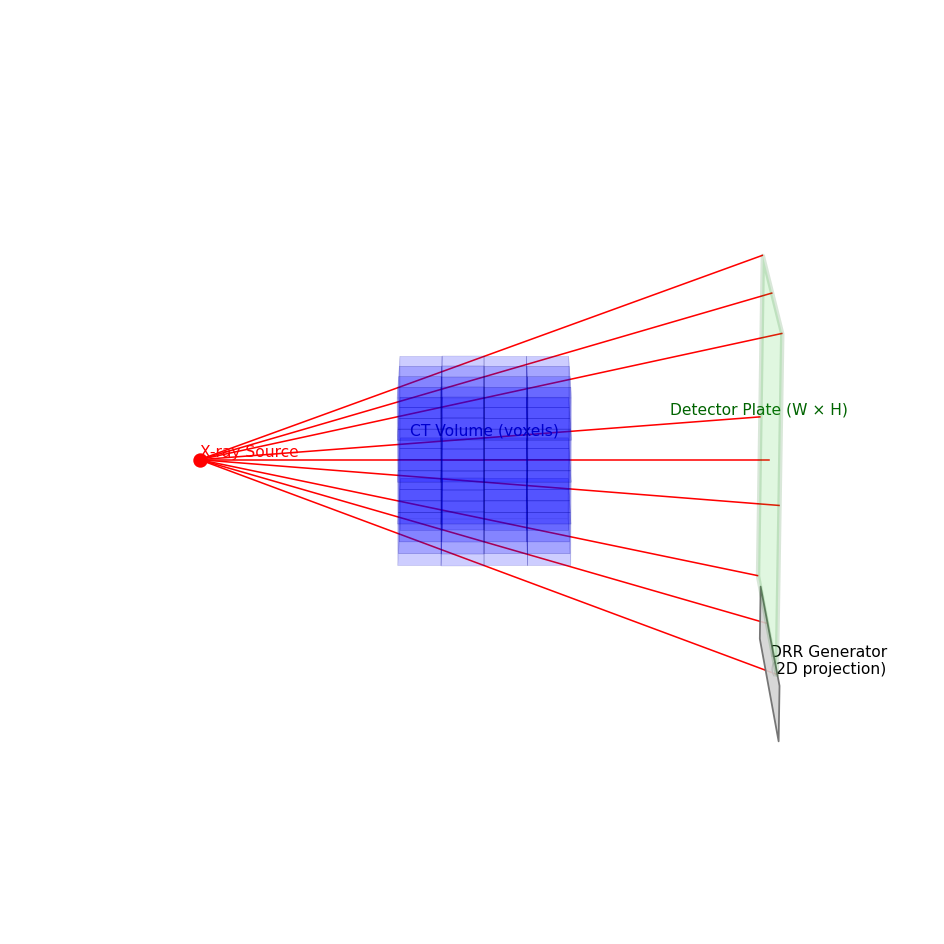

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ---- Scene parameters
source = np.array([0.0, 0.0, 0.0])

xd = 10.0   # detector plane x-position
W, H = 6.0, 6.0   # detector dimensions
cy, cz = 0.0, 0.0

# ---- CT cube parameters
cube_center = np.array([5.0, 0.0, 0.0])  # centered between source and detector
cube_side = 3.0
cube_min = cube_center - cube_side/2
cube_max = cube_center + cube_side/2

# ---- Build detector plane corners
D1 = np.array([xd, cy - H/2, cz - W/2])
D2 = np.array([xd, cy + H/2, cz - W/2])
D3 = np.array([xd, cy + H/2, cz + W/2])
D4 = np.array([xd, cy - H/2, cz + W/2])

# ---- Create figure
fig = plt.figure(figsize=(8, 6), dpi=160)
ax = fig.add_subplot(111, projection='3d')

# ---- Plot source
ax.scatter(*source, s=30, color='red')
ax.text(*source, "X-ray Source", color='red', fontsize=7, ha='left', va='bottom')

# ---- Voxelized CT cube
nx, ny, nz = 4, 4, 4  # voxel grid resolution
xs = np.linspace(cube_min[0], cube_max[0], nx+1)
ys = np.linspace(cube_min[1], cube_max[1], ny+1)
zs = np.linspace(cube_min[2], cube_max[2], nz+1)

for i in range(nx):
    for j in range(ny):
        for k in range(nz):
            x0, x1 = xs[i], xs[i+1]
            y0, y1 = ys[j], ys[j+1]
            z0, z1 = zs[k], zs[k+1]
            verts = [
                [(x0,y0,z0),(x1,y0,z0),(x1,y1,z0),(x0,y1,z0)],
                [(x0,y0,z1),(x1,y0,z1),(x1,y1,z1),(x0,y1,z1)],
                [(x0,y0,z0),(x1,y0,z0),(x1,y0,z1),(x0,y0,z1)],
                [(x0,y1,z0),(x1,y1,z0),(x1,y1,z1),(x0,y1,z1)],
                [(x0,y0,z0),(x0,y1,z0),(x0,y1,z1),(x0,y0,z1)],
                [(x1,y0,z0),(x1,y1,z0),(x1,y1,z1),(x1,y0,z1)]
            ]
            cubelet = Poly3DCollection(verts, alpha=0.1, facecolor='blue', edgecolor='navy', linewidths=0.2)
            ax.add_collection3d(cubelet)

ax.text(cube_center[0], cube_center[1]+cube_side/2+0.2, cube_center[2],
        "CT Volume (voxels)", color='navy', fontsize=7, ha='center')

# ---- Plot detector plane with bold outline
det_verts = [[D1, D2, D3, D4]]
det = Poly3DCollection(det_verts, alpha=0.15, facecolor='limegreen',
                       edgecolor='darkgreen', linewidths=2.0)
ax.add_collection3d(det)
ax.text(xd, cy + H/2 + 0.2, cz, "Detector Plate (W × H)", color='darkgreen', fontsize=7, ha='center')

# ---- DRR Generator block
B1 = np.array([xd + 0.05, cy - H/2, cz - W/2 - 1.2])
B2 = np.array([xd + 0.05, cy + H/2, cz - W/2 - 1.2])
B3 = np.array([xd + 0.05, cy + H/2, cz - W/2 - 0.2])
B4 = np.array([xd + 0.05, cy - H/2, cz - W/2 - 0.2])
block = Poly3DCollection([[B1,B2,B3,B4]], alpha=0.9, facecolor='lightgray',
                         edgecolor='dimgray', linewidths=0.8)
ax.add_collection3d(block)
ax.text(xd + 0.07, cy, cz - W/2 - 0.7, "DRR Generator\n(2D projection)",
        color='black', fontsize=7, ha='left', va='center', rotation=90)

# ---- Rays: reduced number
ny_r, nz_r = 3, 3
ys = np.linspace(cy - H/2, cy + H/2, ny_r)
zs = np.linspace(cz - W/2, cz + W/2, nz_r)
for yy in ys:
    for zz in zs:
        P = np.array([xd, yy, zz])
        ax.plot([source[0], P[0]], [source[1], P[1]], [source[2], P[2]], color='red', linewidth=0.7)

# ---- Clean formatting
ax.set_xlim(-1, 11)
ax.set_ylim(-4, 4)
ax.set_zlim(-4, 4)
ax.set_box_aspect((1.5, 1.0, 1.0))

ax.set_axis_off()
ax.grid(False)

# Orthographic-style schematic
ax.view_init(elev=15, azim=-90)

plt.tight_layout()
plt.show()


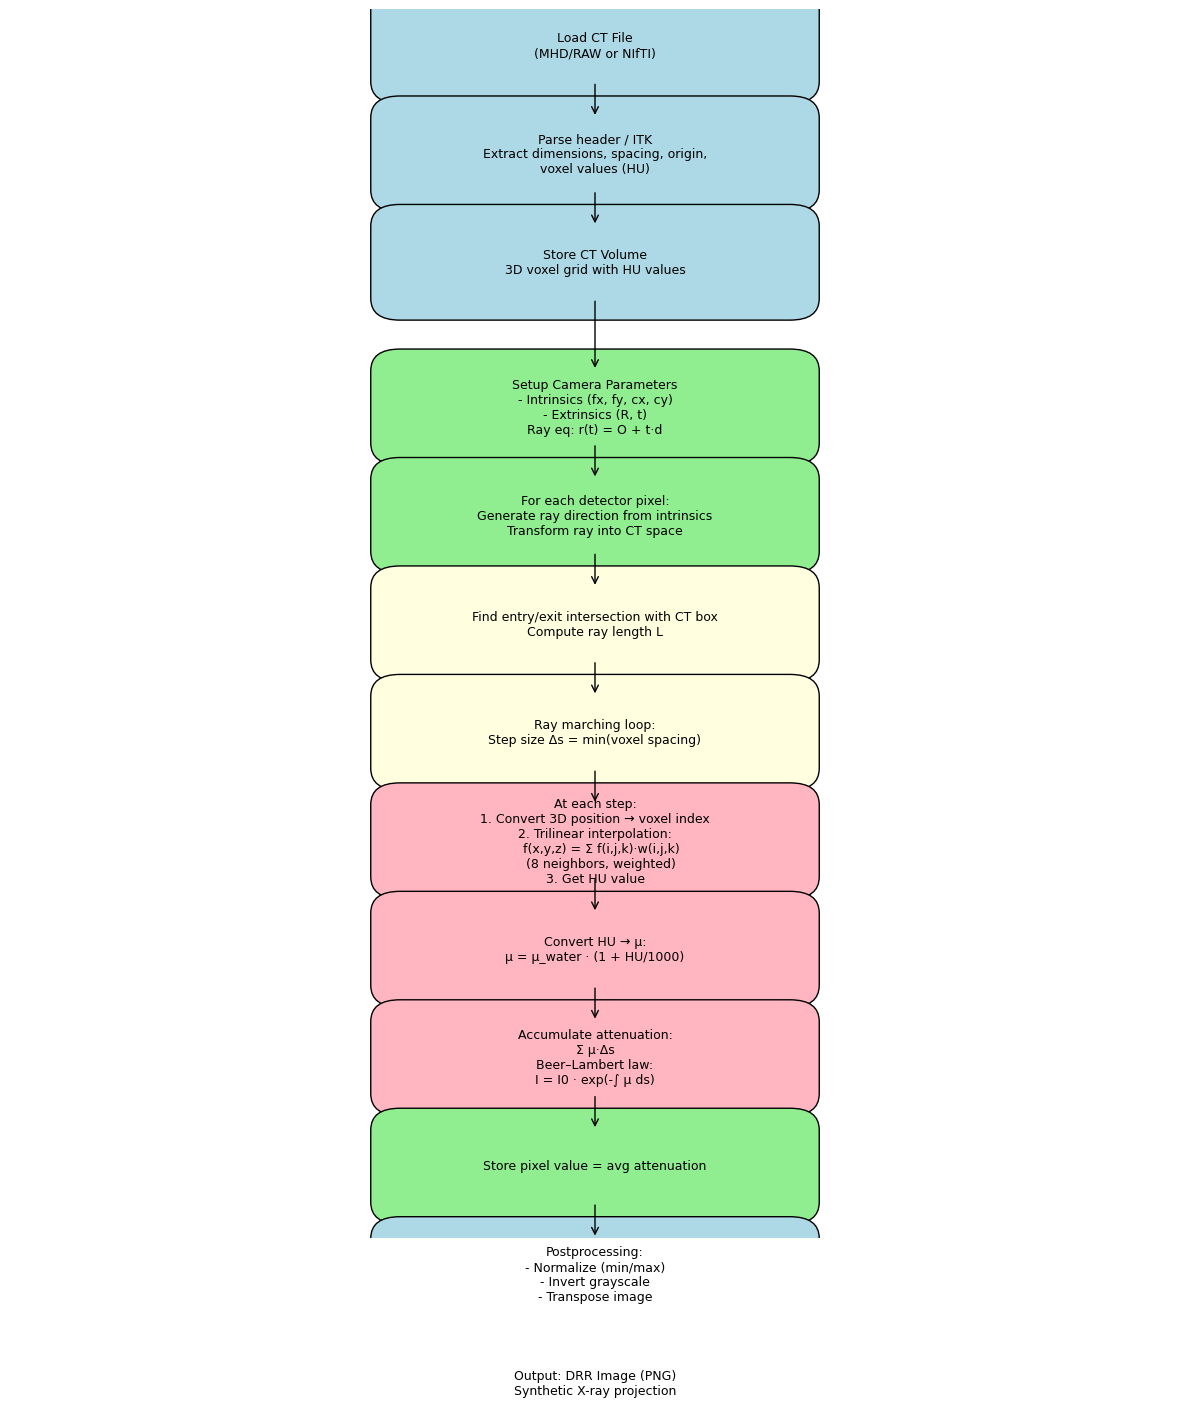

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def add_box(ax, text, xy, color="lightyellow", width=4, height=1.0):
    """Add a labeled box to the diagram."""
    box = FancyBboxPatch(
        (xy[0], xy[1]), width, height,
        boxstyle="round,pad=0.3",
        facecolor=color,
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(xy[0] + width/2, xy[1] + height/2, text,
            ha="center", va="center", fontsize=9, wrap=True)

def add_arrow(ax, start, end):
    """Add an arrow between two points."""
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="->",
        mutation_scale=12,
        linewidth=1,
        color="black"
    )
    ax.add_patch(arrow)

# --- Setup figure ---
fig, ax = plt.subplots(figsize=(12, 14))
ax.set_xlim(0, 12)
ax.set_ylim(-2, 15)
ax.axis("off")

# --- Blocks with decomposition and formulas ---
add_box(ax, "Load CT File\n(MHD/RAW or NIfTI)", (4, 14), color="lightblue")
add_box(ax, "Parse header / ITK\nExtract dimensions, spacing, origin,\nvoxel values (HU)", (4, 12.5), color="lightblue")
add_box(ax, "Store CT Volume\n3D voxel grid with HU values", (4, 11), color="lightblue")

add_box(ax, "Setup Camera Parameters\n- Intrinsics (fx, fy, cx, cy)\n- Extrinsics (R, t)\nRay eq: r(t) = O + t·d", (4, 9), color="lightgreen")

add_box(ax, "For each detector pixel:\nGenerate ray direction from intrinsics\nTransform ray into CT space", (4, 7.5), color="lightgreen")

add_box(ax, "Find entry/exit intersection with CT box\nCompute ray length L", (4, 6), color="lightyellow")

add_box(ax, "Ray marching loop:\nStep size Δs = min(voxel spacing)", (4, 4.5), color="lightyellow")

add_box(ax, "At each step:\n1. Convert 3D position → voxel index\n2. Trilinear interpolation:\n   f(x,y,z) = Σ f(i,j,k)·w(i,j,k)\n   (8 neighbors, weighted)\n3. Get HU value", (4, 3), color="lightpink")

add_box(ax, "Convert HU → μ:\nμ = μ_water · (1 + HU/1000)", (4, 1.5), color="lightpink")

add_box(ax, "Accumulate attenuation:\nΣ μ·Δs\nBeer–Lambert law:\nI = I0 · exp(-∫ μ ds)", (4, 0), color="lightpink")

add_box(ax, "Store pixel value = avg attenuation", (4, -1.5), color="lightgreen")

add_box(ax, "Postprocessing:\n- Normalize (min/max)\n- Invert grayscale\n- Transpose image", (4, -3), color="lightblue")

add_box(ax, "Output: DRR Image (PNG)\nSynthetic X-ray projection", (4, -4.5), color="orange")

# --- Arrows ---
y_positions = [14, 12.5, 11, 9, 7.5, 6, 4.5, 3, 1.5, 0, -1.5, -3, -4.5]
for i in range(len(y_positions)-1):
    add_arrow(ax, (6, y_positions[i]), (6, y_positions[i+1]+1))

plt.tight_layout()
plt.show()


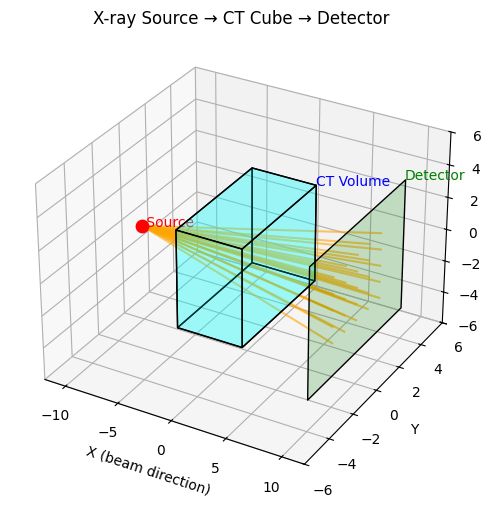

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def plot_xray_system():
    fig = plt.figure(figsize=(10,6))
    ax = fig.add_subplot(111, projection='3d')

    # --- Cube (CT Volume) at origin ---
    cube_size = 6
    cube_min = -cube_size/2
    cube_max = cube_size/2
    r = [cube_min, cube_max]

    # Cube vertices
    vertices = np.array([[x,y,z] for x in r for y in r for z in r])
    faces = [
        [vertices[j] for j in [0,1,3,2]], # bottom
        [vertices[j] for j in [4,5,7,6]], # top
        [vertices[j] for j in [0,1,5,4]], # front
        [vertices[j] for j in [2,3,7,6]], # back
        [vertices[j] for j in [0,2,6,4]], # left
        [vertices[j] for j in [1,3,7,5]]  # right
    ]
    ax.add_collection3d(Poly3DCollection(faces, facecolors='cyan', linewidths=1, edgecolors='k', alpha=0.2))
    ax.text(cube_max, cube_max, cube_max, "CT Volume", color="blue")

    # --- Source on the left ---
    source = np.array([-10, 0, 0])
    ax.scatter(*source, color='red', s=80, label="X-ray Source")
    ax.text(*source, " Source", color="red")

    # --- Detector plane on the right ---
    det_x = 10
    W, H = 8, 8
    corners = np.array([
        [det_x, -H/2, -W/2],
        [det_x, -H/2,  W/2],
        [det_x,  H/2,  W/2],
        [det_x,  H/2, -W/2]
    ])
    ax.add_collection3d(Poly3DCollection([corners], facecolors='green', alpha=0.2, edgecolors='k'))
    ax.text(det_x, H/2, W/2, "Detector", color="green")

    # --- Rays from source through cube to detector ---
    for y in np.linspace(-2,2,5):
        for z in np.linspace(-2,2,5):
            ray_end = np.array([det_x, y, z])
            ax.plot([source[0], ray_end[0]], [source[1], ray_end[1]], [source[2], ray_end[2]], color="orange", alpha=0.6)

    # --- Axes setup ---
    ax.set_xlabel("X (beam direction)")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_xlim([-12, 12])
    ax.set_ylim([-6, 6])
    ax.set_zlim([-6, 6])
    ax.set_title("X-ray Source → CT Cube → Detector")
    plt.show()

# Run visualization
plot_xray_system()


In [ ]:
import numpy as np

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 30            # ray angle (0 = +x)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation from grid centers ----
def bilinear_interp(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0

    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)

    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]

    Q11 = mu_grid[j, i]
    Q21 = mu_grid[j, i+1]
    Q12 = mu_grid[j+1, i]
    Q22 = mu_grid[j+1, i+1]

    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom

    return a*Q11 + b*Q21 + c*Q12 + d*Q22

# ---- Find entry & exit points with ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    # ---- March inside grid ----
    positions = []
    mus = []
    intensities = [I0]
    I = I0
    p = entry_point.copy()

    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))

    for k in range(steps):
        p = p + step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu = bilinear_interp(p[0], p[1])
        I = I*np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)

    # ---- Print results ----
    print("\nStep |      x       y   |   μ    | Intensity")
    print("-----+------------------+--------+-----------")
    for k,(pos,mu,I) in enumerate(zip(positions,mus,intensities[1:])):
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:6.3f} | {I:9.4f}")


Entry point: [-4.          3.46410162]
Exit point : [-3.07179677  4.        ]

Step |      x       y   |   μ    | Intensity
-----+------------------+--------+-----------
   1 |   -3.13    3.96 |  0.146 |    0.8642


Entry point: [-4.          2.18382141]
Exit point : [0.98990968 4.        ]

Step |      x       y   |   μ    | Intensity
-----+------------------+--------+-----------
   1 |   -3.06    2.53 |  0.134 |    0.8747
   2 |   -2.12    2.87 |  0.160 |    0.7451
   3 |   -1.18    3.21 |  0.189 |    0.6171
   4 |   -0.24    3.55 |  0.218 |    0.4961
   5 |    0.70    3.89 |  0.250 |    0.3865


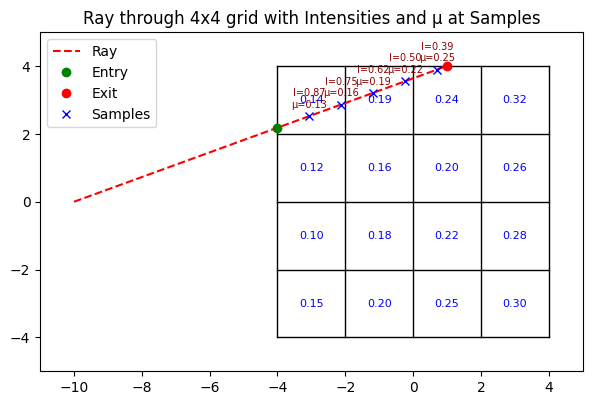

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 20               # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation from grid centers ----
def bilinear_interp(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0

    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)

    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]

    Q11 = mu_grid[j, i]
    Q21 = mu_grid[j, i+1]
    Q12 = mu_grid[j+1, i]
    Q22 = mu_grid[j+1, i+1]

    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom

    return a*Q11 + b*Q21 + c*Q12 + d*Q22

# ---- Find entry & exit points with ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    # ---- March inside grid ----
    positions = []
    mus = []
    intensities = [I0]
    I = I0
    p = entry_point.copy()

    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))

    for k in range(steps):
        p = p + step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu = bilinear_interp(p[0], p[1])
        I = I*np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)

    # ---- Print results ----
    print("\nStep |      x       y   |   μ    | Intensity")
    print("-----+------------------+--------+-----------")
    for k,(pos,mu,I) in enumerate(zip(positions,mus,intensities[1:])):
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:6.3f} | {I:9.4f}")

    # ---- Visualization with Matplotlib ----
    fig, ax = plt.subplots(figsize=(7,7))

    # Draw grid
    for i in range(Nx+1):
        ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
    for j in range(Ny+1):
        ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)

    # Show cell centers with μ values
    for j,yc in enumerate(y_centers):
        for i,xc in enumerate(x_centers):
            ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                    fontsize=8, color='blue')

    # Plot ray path
    ray_line = np.array([source, exit_point])
    ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')

    # Mark entry and exit
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit')

    # Mark sampled positions with μ and I labels
    positions = np.array(positions)
    if len(positions)>0:
        ax.plot(positions[:,0], positions[:,1], 'bx', label='Samples')
        for (x,y),mu,I in zip(positions,mus,intensities[1:]):
            ax.text(x, y+0.25, f"I={I:.2f}\nμ={mu:.2f}",
                    ha='center', fontsize=7, color='darkred')

    ax.set_aspect('equal')
    ax.set_xlim(-11,5)
    ax.set_ylim(-5,5)
    ax.set_title("Ray through 4x4 grid with Intensities and μ at Samples")
    ax.legend()
    plt.show()


Entry point: [-4.  0.]
Exit point : [4. 0.]

Step |      x       y   |   μ    | Intensity
-----+------------------+--------+-----------
   1 |   -4.00    0.00 |  0.080 |    0.9231
   2 |   -3.00    0.00 |  0.110 |    0.8270
   3 |   -2.00    0.00 |  0.140 |    0.7189
   4 |   -1.00    0.00 |  0.170 |    0.6065
   5 |    0.00    0.00 |  0.190 |    0.5016
   6 |    1.00    0.00 |  0.210 |    0.4066
   7 |    2.00    0.00 |  0.240 |    0.3198
   8 |    3.00    0.00 |  0.270 |    0.2441


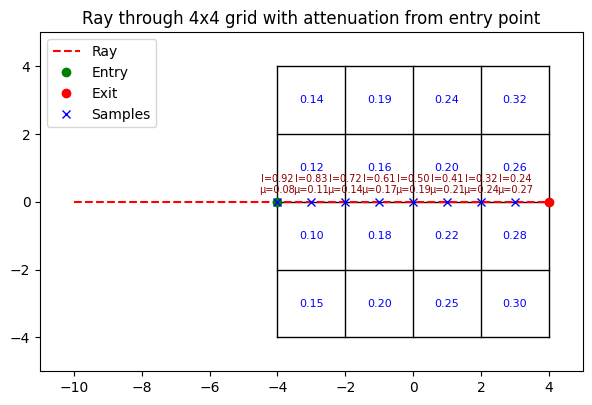

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 0            # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation from grid centers ----
def bilinear_interp(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0
    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]
    Q11, Q21 = mu_grid[j, i], mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]
    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom
    return a*Q11 + b*Q21 + c*Q12 + d*Q22

# ---- Ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    # ---- March inside grid ----
    positions = []
    mus = []
    intensities = []
    I = I0
    p = entry_point.copy()

    # apply attenuation immediately at entry
    mu_entry = bilinear_interp(p[0], p[1])
    I *= np.exp(-mu_entry*step)
    positions.append(tuple(p))
    mus.append(mu_entry)
    intensities.append(I)

    # continue stepping
    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))
    for k in range(1, steps):
        p = entry_point + k*step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu = bilinear_interp(p[0], p[1])
        I *= np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)

    # ---- Print results ----
    print("\nStep |      x       y   |   μ    | Intensity")
    print("-----+------------------+--------+-----------")
    for k,(pos,mu,I) in enumerate(zip(positions,mus,intensities)):
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:6.3f} | {I:9.4f}")

    # ---- Visualization ----
    fig, ax = plt.subplots(figsize=(7,7))

    # Draw grid
    for i in range(Nx+1):
        ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
    for j in range(Ny+1):
        ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)

    # Show μ at centers
    for j,yc in enumerate(y_centers):
        for i,xc in enumerate(x_centers):
            ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                    fontsize=8, color='blue')

    # Ray path
    ray_line = np.array([source, exit_point])
    ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit')

    # Sample points
    positions = np.array(positions)
    if len(positions)>0:
        ax.plot(positions[:,0], positions[:,1], 'bx', label='Samples')
        for (x,y),mu,I in zip(positions,mus,intensities):
            ax.text(x, y+0.25, f"I={I:.2f}\nμ={mu:.2f}",
                    ha='center', fontsize=7, color='darkred')

    ax.set_aspect('equal')
    ax.set_xlim(-11,5)
    ax.set_ylim(-5,5)
    ax.set_title("Ray through 4x4 grid with attenuation from entry point")
    ax.legend()
    plt.show()


Entry point: [-4.  0.]
Exit point : [4. 0.]

Step |      x       y   |   μ    | Intensity  | Interpolation details
-----+------------------+--------+------------+-------------------------------------------
   1 |   -4.00    0.00 |  0.080 |     0.9231 | 0.75*0.10 + -0.25*0.18 + 0.75*0.12 + -0.25*0.16
   2 |   -3.00    0.00 |  0.110 |     0.8270 | 0.50*0.10 + 0.00*0.18 + 0.50*0.12 + 0.00*0.16
   3 |   -2.00    0.00 |  0.140 |     0.7189 | 0.25*0.10 + 0.25*0.18 + 0.25*0.12 + 0.25*0.16
   4 |   -1.00    0.00 |  0.170 |     0.6065 | 0.00*0.10 + 0.50*0.18 + 0.00*0.12 + 0.50*0.16
   5 |    0.00    0.00 |  0.190 |     0.5016 | 0.25*0.18 + 0.25*0.22 + 0.25*0.16 + 0.25*0.20
   6 |    1.00    0.00 |  0.210 |     0.4066 | 0.00*0.18 + 0.50*0.22 + 0.00*0.16 + 0.50*0.20
   7 |    2.00    0.00 |  0.240 |     0.3198 | 0.25*0.22 + 0.25*0.28 + 0.25*0.20 + 0.25*0.26
   8 |    3.00    0.00 |  0.270 |     0.2441 | 0.00*0.22 + 0.50*0.28 + 0.00*0.20 + 0.50*0.26


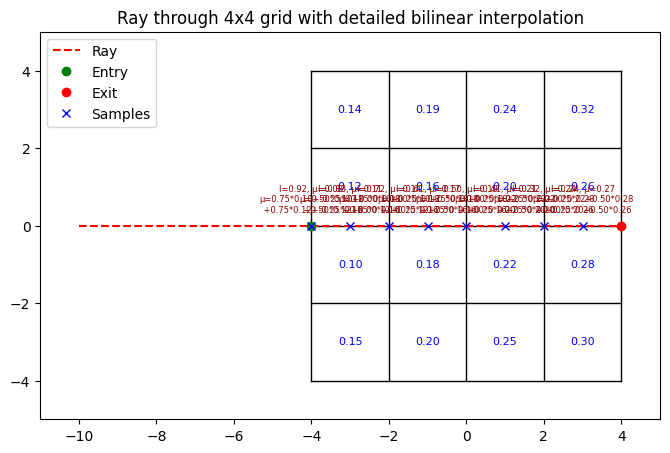

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 0                # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation with details ----
def bilinear_interp_details(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0, None, None, None

    # Find indices of square enclosing (x,y)
    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]

    # Corner values
    Q11, Q21 = mu_grid[j, i],   mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]

    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom

    mu = a*Q11 + b*Q21 + c*Q12 + d*Q22
    return mu, (a,b,c,d), (Q11,Q21,Q12,Q22), (x1,x2,y1,y2)

# ---- Ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    # ---- March inside grid ----
    positions = []
    mus = []
    intensities = []
    interp_details = []
    I = I0

    # apply attenuation immediately at entry
    mu_entry, weights, Qs, corners = bilinear_interp_details(entry_point[0], entry_point[1])
    I *= np.exp(-mu_entry*step)
    positions.append(tuple(entry_point))
    mus.append(mu_entry)
    intensities.append(I)
    interp_details.append((weights,Qs))

    # continue stepping
    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))
    for k in range(1, steps):
        p = entry_point + k*step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu, weights, Qs, corners = bilinear_interp_details(p[0], p[1])
        I *= np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)
        interp_details.append((weights,Qs))

    # ---- Print results with breakdown ----
    print("\nStep |      x       y   |   μ    | Intensity  | Interpolation details")
    print("-----+------------------+--------+------------+-------------------------------------------")
    for k,(pos,mu,I,details) in enumerate(zip(positions,mus,intensities,interp_details)):
        weights,Qs = details
        a,b,c,d = weights
        Q11,Q21,Q12,Q22 = Qs
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:6.3f} | {I:10.4f} | "
              f"{a:.2f}*{Q11:.2f} + {b:.2f}*{Q21:.2f} + {c:.2f}*{Q12:.2f} + {d:.2f}*{Q22:.2f}")

    # ---- Visualization ----
    fig, ax = plt.subplots(figsize=(8,8))

    # Draw grid
    for i in range(Nx+1):
        ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
    for j in range(Ny+1):
        ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)

    # Show μ at centers
    for j,yc in enumerate(y_centers):
        for i,xc in enumerate(x_centers):
            ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                    fontsize=8, color='blue')

    # Ray path
    ray_line = np.array([source, exit_point])
    ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit')

    # Sample points with details
    positions = np.array(positions)
    if len(positions)>0:
        ax.plot(positions[:,0], positions[:,1], 'bx', label='Samples')
        for (x,y),mu,I,details in zip(positions,mus,intensities,interp_details):
            weights,Qs = details
            a,b,c,d = weights
            Q11,Q21,Q12,Q22 = Qs
            ax.text(x, y+0.35,
                    f"I={I:.2f}, μ={mu:.2f}\nμ={a:.2f}*{Q11:.2f}+{b:.2f}*{Q21:.2f}\n +{c:.2f}*{Q12:.2f}+{d:.2f}*{Q22:.2f}",
                    ha='center', fontsize=6, color='darkred')

    ax.set_aspect('equal')
    ax.set_xlim(-11,5)
    ax.set_ylim(-5,5)
    ax.set_title("Ray through 4x4 grid with detailed bilinear interpolation")
    ax.legend()
    plt.show()


Entry point: [-4.         -2.79784595]
Exit point : [-1.42197232 -4.        ]

Step |      x       y   |   μ    | Intensity  | Centers involved (coord, μ)
-----+------------------+--------+------------+--------------------------------
   1 |   -4.00   -2.80 |  0.118 |     0.8883 | (-3,-3):0.15, (-1,-3):0.20, (-3,-1):0.10, (-1,-1):0.18
   2 |   -3.09   -3.22 |  0.153 |     0.7620 | (-3,-3):0.15, (-1,-3):0.20, (-3,-1):0.10, (-1,-1):0.18
   3 |   -2.19   -3.64 |  0.182 |     0.6349 | (-3,-3):0.15, (-1,-3):0.20, (-3,-1):0.10, (-1,-1):0.18


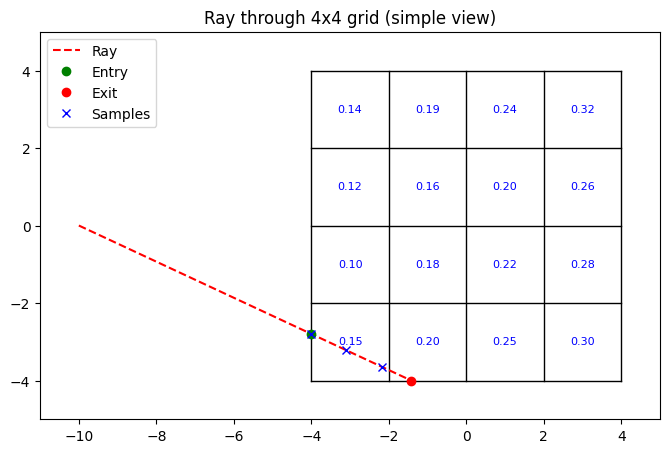

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = -25               # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation with details ----
def bilinear_interp_details(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0, None

    # Find indices of square enclosing (x,y)
    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]

    # Corner values
    Q11, Q21 = mu_grid[j, i],   mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]

    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom

    mu = a*Q11 + b*Q21 + c*Q12 + d*Q22
    centers = [((x1,y1),Q11), ((x2,y1),Q21), ((x1,y2),Q12), ((x2,y2),Q22)]
    return mu, centers

# ---- Ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    # ---- March inside grid ----
    positions, mus, intensities, centers_used = [], [], [], []
    I = I0

    # apply attenuation immediately at entry
    mu_entry, centers = bilinear_interp_details(entry_point[0], entry_point[1])
    I *= np.exp(-mu_entry*step)
    positions.append(tuple(entry_point))
    mus.append(mu_entry)
    intensities.append(I)
    centers_used.append(centers)

    # continue stepping
    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))
    for k in range(1, steps):
        p = entry_point + k*step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu, centers = bilinear_interp_details(p[0], p[1])
        I *= np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)
        centers_used.append(centers)

    # ---- Print results ----
    print("\nStep |      x       y   |   μ    | Intensity  | Centers involved (coord, μ)")
    print("-----+------------------+--------+------------+--------------------------------")
    for k,(pos,mu,I,centers) in enumerate(zip(positions,mus,intensities,centers_used)):
        centers_str = ", ".join([f"({cx:.0f},{cy:.0f}):{q:.2f}" for (cx,cy),q in centers])
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:6.3f} | {I:10.4f} | {centers_str}")

    # ---- Visualization ----
    fig, ax = plt.subplots(figsize=(8,8))

    # Draw grid
    for i in range(Nx+1):
        ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
    for j in range(Ny+1):
        ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)

    # Show μ at centers
    for j,yc in enumerate(y_centers):
        for i,xc in enumerate(x_centers):
            ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                    fontsize=8, color='blue')

    # Ray path
    ray_line = np.array([source, exit_point])
    ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit')

    # Sample points
    positions = np.array(positions)
    if len(positions)>0:
        ax.plot(positions[:,0], positions[:,1], 'bx', label='Samples')

    ax.set_aspect('equal')
    ax.set_xlim(-11,5)
    ax.set_ylim(-5,5)
    ax.set_title("Ray through 4x4 grid (simple view)")
    ax.legend()
    plt.show()

Detector intersection at x=10: [10.          9.32615316]
Entry point in grid: [-4.          2.79784595]
Exit point  in grid: [-1.42197232  4.        ]


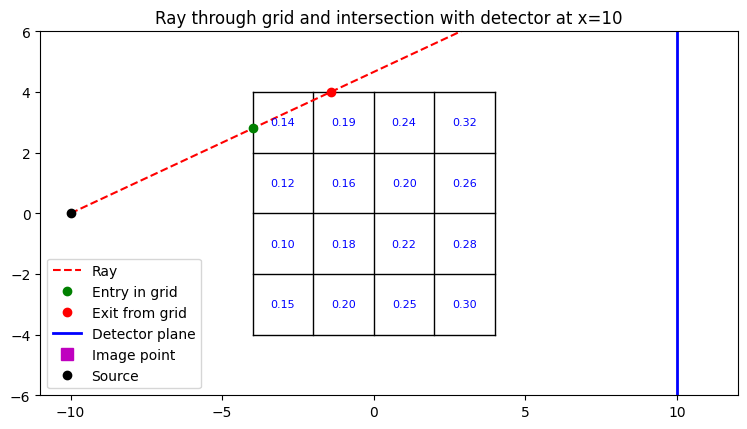

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                      # initial intensity
step = 1.0                    # step size [cm]
source = np.array([-10.0, 0.0])  # ray source (you can change this)
angle_deg = 25                # ray angle in degrees (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Ray-plane (detector at x=10) intersection ----
det_x = 10.0
if abs(direction[0]) < 1e-9:
    print("Ray is vertical, will never hit x=10 detector.")
else:
    t_det = (det_x - source[0]) / direction[0]
    detector_point = source + t_det * direction
    print(f"Detector intersection at x=10: {detector_point}")

# ---- Ray-box intersection (for attenuation simulation) ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point in grid: {entry_point}")
    print(f"Exit point  in grid: {exit_point}")

# ---- Visualization ----
fig, ax = plt.subplots(figsize=(9,7))

# Draw grid
for i in range(Nx+1):
    ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
for j in range(Ny+1):
    ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)

# Show μ at centers
for j,yc in enumerate(y_centers):
    for i,xc in enumerate(x_centers):
        ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                fontsize=8, color='blue')

# Ray path up to detector
ray_line = np.array([source, detector_point])
ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')

# Entry & exit points
if t_entry is not None:
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry in grid')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit from grid')

# Detector line at x=10
ax.plot([det_x, det_x], [y_min-2, y_max+2], 'b-', lw=2, label='Detector plane')

# Intersection point on detector
ax.plot(detector_point[0], detector_point[1], 'ms', markersize=8, label='Image point')

# Source
ax.plot(source[0], source[1], 'ko', label='Source')

ax.set_aspect('equal')
ax.set_xlim(-11, 12)
ax.set_ylim(-6, 6)
ax.set_title("Ray through grid and intersection with detector at x=10")
ax.legend()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =====================
# Adjustable parameters
# =====================
I0 = 1.0                        # initial intensity
step = 1.0                      # nominal step size [cm]
source = np.array([-10.0, 0.0]) # ray source (changeable)
angle_deg = 25                  # ray angle in degrees (0 = +x direction)
det_x = 10.0                    # detector plane at x = 10

# =====================
# Derived quantities
# =====================
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit direction

print(f"Direction (unit) from angle {angle_deg}°: d = ({direction[0]:.6f}, {direction[1]:.6f})")

# =====================
# Grid definition
# =====================
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4.0, 4.0
y_min, y_max = -4.0, 4.0
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])

# =====================
# Bilinear interpolation
# =====================
def bilinear_interp_details(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0, []
    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]
    Q11, Q21 = mu_grid[j, i],   mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]
    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom
    mu = a*Q11 + b*Q21 + c*Q12 + d*Q22
    centers = [((x1,y1),Q11), ((x2,y1),Q21), ((x1,y2),Q12), ((x2,y2),Q22)]
    return mu, centers

# =====================
# Ray-box intersection
# =====================
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for axis in range(2):
        lo, hi = bounds[axis]
        if abs(direction[axis]) < 1e-12:
            if origin[axis] < lo or origin[axis] > hi:
                return None, None
        else:
            t1 = (lo - origin[axis]) / direction[axis]
            t2 = (hi - origin[axis]) / direction[axis]
            t_near, t_far = min(t1, t2), max(t1, t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min, x_max), (y_min, y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

# Detector intersection
if abs(direction[0]) < 1e-12:
    detector_point = None
    print("Ray is vertical, won’t intersect detector plane.")
else:
    t_det = (det_x - source[0]) / direction[0]
    detector_point = source + t_det * direction
    print(f"Detector intersection: P_det = ({detector_point[0]:.3f}, {detector_point[1]:.3f})")

if t_entry is None:
    print("Ray does not intersect grid.")
    entry_point = exit_point = None
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Grid entry: P_in = ({entry_point[0]:.3f}, {entry_point[1]:.3f})")
    print(f"Grid exit : P_out= ({exit_point[0]:.3f}, {exit_point[1]:.3f})")

# =====================
# Marching inside grid
# =====================
I_final = I0
if t_entry is not None:
    L_total = np.linalg.norm(exit_point - entry_point)
    num_full = int(np.floor(L_total / step))
    distances = [0.0] + [i*step for i in range(1, num_full+1)]
    if L_total - num_full*step > 1e-9:
        distances.append(num_full*step)

    print("\nPer-step calculations:")
    print("k |   x_k     y_k   | Δs_k | μ(x_k,y_k) | I_k formula | I_k | Centers")
    print("--+-----------------+------+------------+-------------+-----+--------")

    I_prev = I0
    for idx, s_start in enumerate(distances, start=1):
        s_end = min(s_start + step, L_total)
        ds = s_end - s_start
        p = entry_point + s_start*direction
        mu, centers = bilinear_interp_details(p[0], p[1])
        I_next = I_prev * np.exp(-mu * ds)

        centers_str = ", ".join([f"({cx},{cy}):{q:.2f}" for (cx,cy),q in centers])
        print(f"{idx} | {p[0]:7.3f} {p[1]:7.3f} | {ds:4.2f} | {mu:10.4f} | I={I_prev:.4f}*exp(-{mu:.3f}*{ds:.3f}) | {I_next:.4f} | {centers_str}")

        I_prev = I_next
    I_final = I_prev

print(f"\nFinal intensity at detector (after grid) = {I_final:.4f}")


Direction (unit) from angle 25°: d = (0.906308, 0.422618)
Detector intersection: P_det = (10.000, 9.326)
Grid entry: P_in = (-4.000, 2.798)
Grid exit : P_out= (-1.422, 4.000)

Per-step calculations:
k |   x_k     y_k   | Δs_k | μ(x_k,y_k) | I_k formula | I_k | Centers
--+-----------------+------+------------+-------------+-----+--------
1 |  -4.000   2.798 | 1.00 |     0.1135 | I=1.0000*exp(-0.113*1.000) | 0.8927 | (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19
2 |  -3.094   3.220 | 1.00 |     0.1398 | I=0.8927*exp(-0.140*1.000) | 0.7762 | (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19
3 |  -2.187   3.643 | 0.84 |     0.1681 | I=0.7762*exp(-0.168*0.845) | 0.6735 | (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19
4 |  -2.187   3.643 | 0.84 |     0.1681 | I=0.6735*exp(-0.168*0.845) | 0.5844 | (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

Final intensity at detector (after grid) = 0.5844


Entry point: [-4.          2.18382141]
Exit point : [0.98990968 4.        ]

Step |      x       y   |   μ(x,y)  | Intensity  | Bilinear interpolation details
-----+------------------+-----------+------------+---------------------------------------------
   1 |   -4.00    2.18 |    0.1089 |     0.8968 |
     Interp: 0.61*0.12 + -0.20*0.16 + 0.89*0.14 + -0.30*0.19
     Centers: (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

   2 |   -3.06    2.53 |    0.1338 |     0.7845 |
     Interp: 0.24*0.12 + -0.01*0.16 + 0.79*0.14 + -0.02*0.19
     Centers: (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

   3 |   -2.12    2.87 |    0.1604 |     0.6683 |
     Interp: 0.04*0.12 + 0.03*0.16 + 0.52*0.14 + 0.41*0.19
     Centers: (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

   4 |   -1.18    3.21 |    0.1885 |     0.5534 |
     Interp: -0.01*0.12 + -0.10*0.16 + 0.10*0.14 + 1.00*0.19
     Centers: (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

   5 |   -0.24    3.55 |    0.2183 |   

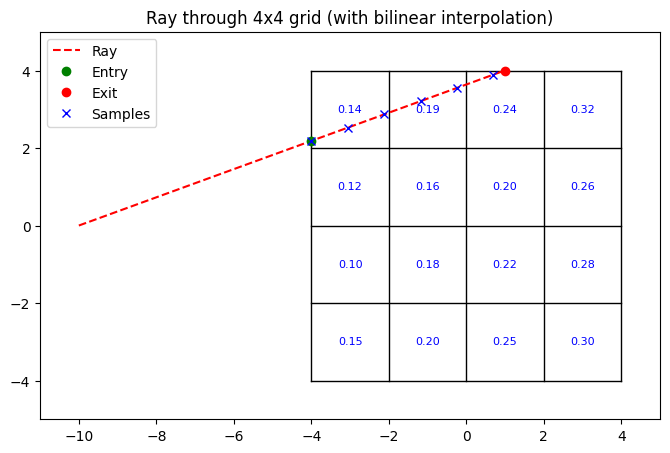

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                     # initial intensity
step = 1.0                   # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 20               # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation with weights ----
def bilinear_interp_details(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0, None, None

    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]

    # Corner values
    Q11, Q21 = mu_grid[j, i],   mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]

    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom

    mu = a*Q11 + b*Q21 + c*Q12 + d*Q22
    centers = [((x1,y1),Q11), ((x2,y1),Q21), ((x1,y2),Q12), ((x2,y2),Q22)]
    weights = (a,b,c,d)
    return mu, centers, weights

# ---- Ray-box intersection ----
def ray_box_intersection(origin, direction, bounds):
    tmin, tmax = -np.inf, np.inf
    for i in range(2):  # x and y
        if abs(direction[i]) < 1e-9:
            if origin[i] < bounds[i][0] or origin[i] > bounds[i][1]:
                return None, None
        else:
            t1 = (bounds[i][0] - origin[i]) / direction[i]
            t2 = (bounds[i][1] - origin[i]) / direction[i]
            t_near, t_far = min(t1,t2), max(t1,t2)
            tmin = max(tmin, t_near)
            tmax = min(tmax, t_far)
            if tmin > tmax:
                return None, None
    return tmin, tmax

bounds = [(x_min,x_max),(y_min,y_max)]
t_entry, t_exit = ray_box_intersection(source, direction, bounds)

if t_entry is None:
    print("Ray does not intersect the grid.")
else:
    entry_point = source + t_entry*direction
    exit_point  = source + t_exit*direction
    print(f"Entry point: {entry_point}")
    print(f"Exit point : {exit_point}")

    positions, mus, intensities, centers_used, weights_used = [], [], [], [], []
    I = I0

    # apply attenuation immediately at entry
    mu_entry, centers, weights = bilinear_interp_details(entry_point[0], entry_point[1])
    I *= np.exp(-mu_entry*step)
    positions.append(tuple(entry_point))
    mus.append(mu_entry)
    intensities.append(I)
    centers_used.append(centers)
    weights_used.append(weights)

    # continue stepping
    L = np.linalg.norm(exit_point - entry_point)
    steps = int(np.ceil(L/step))
    for k in range(1, steps):
        p = entry_point + k*step*direction
        if np.any(p < [x_min,y_min]) or np.any(p > [x_max,y_max]):
            break
        mu, centers, weights = bilinear_interp_details(p[0], p[1])
        I *= np.exp(-mu*step)
        positions.append(tuple(p))
        mus.append(mu)
        intensities.append(I)
        centers_used.append(centers)
        weights_used.append(weights)

    # ---- Print results with details ----
    print("\nStep |      x       y   |   μ(x,y)  | Intensity  | Bilinear interpolation details")
    print("-----+------------------+-----------+------------+---------------------------------------------")
    for k,(pos,mu,I,centers,w) in enumerate(zip(positions,mus,intensities,centers_used,weights_used)):
        a,b,c,d = w
        centers_str = ", ".join([f"({cx:.0f},{cy:.0f}):{q:.2f}" for (cx,cy),q in centers])
        print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:9.4f} | {I:10.4f} |")
        print(f"     Interp: {a:.2f}*{centers[0][1]:.2f} + {b:.2f}*{centers[1][1]:.2f} + "
              f"{c:.2f}*{centers[2][1]:.2f} + {d:.2f}*{centers[3][1]:.2f}")
        print(f"     Centers: {centers_str}\n")

    # ---- Visualization ----
    fig, ax = plt.subplots(figsize=(8,8))
    for i in range(Nx+1):
        ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
    for j in range(Ny+1):
        ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)
    for j,yc in enumerate(y_centers):
        for i,xc in enumerate(x_centers):
            ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center',
                    fontsize=8, color='blue')

    ray_line = np.array([source, exit_point])
    ax.plot(ray_line[:,0], ray_line[:,1], 'r--', label='Ray')
    ax.plot(entry_point[0], entry_point[1], 'go', label='Entry')
    ax.plot(exit_point[0], exit_point[1], 'ro', label='Exit')
    positions_np = np.array(positions)
    if len(positions_np)>0:
        ax.plot(positions_np[:,0], positions_np[:,1], 'bx', label='Samples')

    ax.set_aspect('equal')
    ax.set_xlim(-11,5)
    ax.set_ylim(-5,5)
    ax.set_title("Ray through 4x4 grid (with bilinear interpolation)")
    ax.legend()
    plt.show()



--- Ray–Grid Intersection Details ---
Ray: r(t) = (-10.000,0.000) + t*(0.939693,0.342020),  t >= 0
Grid box: x in [-4,4], y in [-4,4]
t to hit verticals: x=-4 -> 6.385067, x=4 -> 14.898489
t to hit horizontals: y=-4 -> -11.695218, y=4 -> 11.695218
Near t (x): 6.385067 at x=-4,  Far t (x): 14.898489 at x=4
Near t (y): -11.695218 at y=-4,  Far t (y): 11.695218 at y=4
Entry t = 6.385067 at side x=-4 -> P_in = (-4.0000,2.1838)
Exit  t = 11.695218 at side y=4  -> P_out= (0.9899,4.0000)
-------------------------------------

Step |      x       y   |   μ(x,y)  | Intensity  | Bilinear interpolation details
-----+------------------+-----------+------------+---------------------------------------------
   1 |   -4.00    2.18 |    0.1089 |     0.8968 |
     Interp: 0.61*0.12 + -0.20*0.16 + 0.89*0.14 + -0.30*0.19
     Centers: (-3,1):0.12, (-1,1):0.16, (-3,3):0.14, (-1,3):0.19

   2 |   -3.06    2.53 |    0.1338 |     0.7845 |
     Interp: 0.24*0.12 + -0.01*0.16 + 0.79*0.14 + -0.02*0.19
     Cen

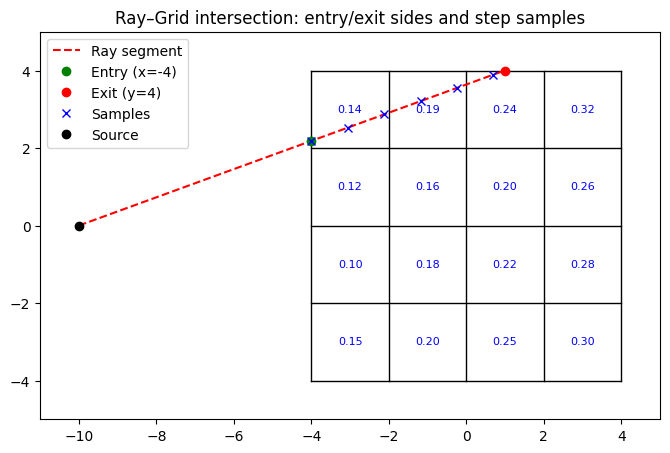

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
I0 = 1.0                      # initial intensity
step = 1.0                    # step size [cm]
source = np.array([-10.0, 0.0])  # ray source
angle_deg = 20                # ray angle (0 = +x direction)
angle_rad = np.deg2rad(angle_deg)
direction = np.array([np.cos(angle_rad), np.sin(angle_rad)])  # unit vector

# Grid: 4x4 cells, 8x8 cm total, centered at (0,0)
Nx, Ny = 4, 4
cell_size = 2.0
x_min, x_max = -4, 4
y_min, y_max = -4, 4
x_centers = np.array([-3, -1, 1, 3])
y_centers = np.array([-3, -1, 1, 3])

# Example attenuation coefficients μ at centers
mu_grid = np.array([
    [0.15, 0.20, 0.25, 0.30],
    [0.10, 0.18, 0.22, 0.28],
    [0.12, 0.16, 0.20, 0.26],
    [0.14, 0.19, 0.24, 0.32]
])  # shape (Ny,Nx)

# ---- Helper: bilinear interpolation with weights ----
def bilinear_interp_details(x, y):
    if x < x_min or x > x_max or y < y_min or y > y_max:
        return 0.0, None, None
    i = np.searchsorted(x_centers, x) - 1
    j = np.searchsorted(y_centers, y) - 1
    i = np.clip(i, 0, Nx-2)
    j = np.clip(j, 0, Ny-2)
    x1, x2 = x_centers[i], x_centers[i+1]
    y1, y2 = y_centers[j], y_centers[j+1]
    Q11, Q21 = mu_grid[j, i],   mu_grid[j, i+1]
    Q12, Q22 = mu_grid[j+1, i], mu_grid[j+1, i+1]
    denom = (x2-x1)*(y2-y1)
    a = (x2-x)*(y2-y)/denom
    b = (x-x1)*(y2-y)/denom
    c = (x2-x)*(y-y1)/denom
    d = (x-x1)*(y-y1)/denom
    mu = a*Q11 + b*Q21 + c*Q12 + d*Q22
    centers = [((x1,y1),Q11), ((x2,y1),Q21), ((x1,y2),Q12), ((x2,y2),Q22)]
    weights = (a,b,c,d)
    return mu, centers, weights

# ---- Verbose ray-box intersection (shows how entry & exit are found) ----
def ray_box_intersection_verbose(origin, d, xmin, xmax, ymin, ymax):
    x0, y0 = origin
    dx, dy = d

    # t values to hit vertical lines x = xmin, x = xmax
    tx_list = []
    if abs(dx) < 1e-12:
        tx_list = [(np.inf, 'x=parallel (no hit)')]
    else:
        tx_list = [((xmin - x0)/dx, f'x={xmin}'), ((xmax - x0)/dx, f'x={xmax}')]

    # t values to hit horizontal lines y = ymin, y = ymax
    ty_list = []
    if abs(dy) < 1e-12:
        ty_list = [(np.inf, 'y=parallel (no hit)')]
    else:
        ty_list = [((ymin - y0)/dy, f'y={ymin}'), ((ymax - y0)/dy, f'y={ymax}')]

    # For each axis, compute "near" (min) and "far" (max)
    # and remember which side gives near/far
    def near_far(tsides):
        if len(tsides) == 1:   # parallel
            return (np.inf, 'none'), (-np.inf, 'none')
        (t1, s1), (t2, s2) = tsides
        if t1 <= t2:
            return (t1, s1), (t2, s2)
        else:
            return (t2, s2), (t1, s1)

    (tx_near, sx_near), (tx_far, sx_far) = near_far(tx_list)
    (ty_near, sy_near), (ty_far, sy_far) = near_far(ty_list)

    # Entry is the max of the nears; exit is the min of the fars
    t_entry = max(tx_near, ty_near)
    t_exit  = min(tx_far,  ty_far)

    # Which side is the entry/exit?
    entry_side = sx_near if np.isclose(t_entry, tx_near, atol=1e-10) else sy_near
    exit_side  = sx_far  if np.isclose(t_exit,  tx_far,  atol=1e-10) else sy_far

    # Print a small report
    print("\n--- Ray–Grid Intersection Details ---")
    print(f"Ray: r(t) = ({x0:.3f},{y0:.3f}) + t*({dx:.6f},{dy:.6f}),  t >= 0")
    print(f"Grid box: x in [{xmin},{xmax}], y in [{ymin},{ymax}]")
    if len(tx_list) == 2:
        print(f"t to hit verticals: {tx_list[0][1]} -> {tx_list[0][0]:.6f}, {tx_list[1][1]} -> {tx_list[1][0]:.6f}")
    else:
        print("Ray parallel to verticals (no hit).")
    if len(ty_list) == 2:
        print(f"t to hit horizontals: {ty_list[0][1]} -> {ty_list[0][0]:.6f}, {ty_list[1][1]} -> {ty_list[1][0]:.6f}")
    else:
        print("Ray parallel to horizontals (no hit).")

    print(f"Near t (x): {tx_near:.6f} at {sx_near},  Far t (x): {tx_far:.6f} at {sx_far}")
    print(f"Near t (y): {ty_near:.6f} at {sy_near},  Far t (y): {ty_far:.6f} at {sy_far}")

    if t_entry > t_exit or t_exit < 0:
        print("=> No forward intersection with the grid.")
        return None

    pin  = origin + t_entry*d
    pout = origin + t_exit*d
    print(f"Entry t = {t_entry:.6f} at side {entry_side} -> P_in = ({pin[0]:.4f},{pin[1]:.4f})")
    print(f"Exit  t = {t_exit:.6f} at side {exit_side}  -> P_out= ({pout[0]:.4f},{pout[1]:.4f})")
    print("-------------------------------------\n")
    return (t_entry, t_exit, pin, pout, entry_side, exit_side)

# ---- Compute entry/exit (verbose) ----
res = ray_box_intersection_verbose(source, direction, x_min, x_max, y_min, y_max)
if not res:
    raise SystemExit("Ray does not intersect the grid.")
t_entry, t_exit, entry_point, exit_point, entry_side, exit_side = res

# ---- March inside grid from entry (Δs = 1 cm, last step partial if needed) ----
positions, mus, intensities, centers_used, weights_used = [], [], [], [], []
I = I0

# Apply attenuation immediately at entry (first segment starts at entry)
mu_entry, centers, weights = bilinear_interp_details(entry_point[0], entry_point[1])
I *= np.exp(-mu_entry*step)
positions.append(tuple(entry_point))
mus.append(mu_entry)
intensities.append(I)
centers_used.append(centers)
weights_used.append(weights)

# Continue stepping
L = np.linalg.norm(exit_point - entry_point)
steps = int(np.ceil(L/step))
for k in range(1, steps):
    p = entry_point + k*step*direction
    if np.any(p < [x_min, y_min]) or np.any(p > [x_max, y_max]):
        break
    mu, centers, weights = bilinear_interp_details(p[0], p[1])
    I *= np.exp(-mu*step)
    positions.append(tuple(p))
    mus.append(mu)
    intensities.append(I)
    centers_used.append(centers)
    weights_used.append(weights)

# ---- Print stepwise details ----
print("Step |      x       y   |   μ(x,y)  | Intensity  | Bilinear interpolation details")
print("-----+------------------+-----------+------------+---------------------------------------------")
for k,(pos,mu,I,centers,w) in enumerate(zip(positions,mus,intensities,centers_used,weights_used)):
    a,b,c,d = w
    centers_str = ", ".join([f"({cx:.0f},{cy:.0f}):{q:.2f}" for (cx,cy),q in centers])
    print(f"{k+1:4d} | {pos[0]:7.2f} {pos[1]:7.2f} | {mu:9.4f} | {I:10.4f} |")
    print(f"     Interp: {a:.2f}*{centers[0][1]:.2f} + {b:.2f}*{centers[1][1]:.2f} + "
          f"{c:.2f}*{centers[2][1]:.2f} + {d:.2f}*{centers[3][1]:.2f}")
    print(f"     Centers: {centers_str}\n")

# ---- Visualization ----
fig, ax = plt.subplots(figsize=(8,8))
# Grid lines
for i in range(Nx+1):
    ax.plot([x_min+i*cell_size, x_min+i*cell_size],[y_min,y_max],'k-',lw=1)
for j in range(Ny+1):
    ax.plot([x_min,x_max],[y_min+j*cell_size,y_min+j*cell_size],'k-',lw=1)
# μ at centers
for j,yc in enumerate(y_centers):
    for i,xc in enumerate(x_centers):
        ax.text(xc, yc, f"{mu_grid[j,i]:.2f}", ha='center', va='center', fontsize=8, color='blue')
# Ray + entry/exit + samples
ax.plot([source[0], exit_point[0]], [source[1], exit_point[1]], 'r--', label='Ray segment')
ax.plot(entry_point[0], entry_point[1], 'go', label=f'Entry ({entry_side})')
ax.plot(exit_point[0], exit_point[1], 'ro',  label=f'Exit ({exit_side})')
P = np.array(positions)
if len(P)>0:
    ax.plot(P[:,0], P[:,1], 'bx', label='Samples')
# Source
ax.plot(source[0], source[1], 'ko', label='Source')

ax.set_aspect('equal')
ax.set_xlim(-11,5)
ax.set_ylim(-5,5)
ax.set_title("Ray–Grid intersection: entry/exit sides and step samples")
ax.legend()
plt.show()
